# 3. XGBoost — Predicting Airline Satisfaction

Primer modelo de árboles del episodio. El logit de `2_logit.ipynb` llegó a **CV AUC = 0,94908**, pero
para eso hubo que construirle a mano todo lo que el EDA mostró: tramos de edad y distancia, umbrales
de demora, el 0 de la encuesta como categoría aparte y cada nota con su propio coeficiente. Sus dos
límites:

- **Interacciones**: sólo ve las que se le dan hechas (los cruces con el tipo de viaje), y de a pares.
- **Los viajes personales**: dentro de ese segmento el AUC cae a ~0,80, contra ~0,92 en los de
  trabajo. El efecto de cada variable es distinto en un segmento y en otro, y un modelo aditivo no
  puede representarlo.

Un ensamble de árboles resuelve las dos cosas solo: parte cada ordinal donde le conviene (el 0 de la
encuesta queda aislado con un corte) y arma interacciones a cualquier profundidad.

- **Categóricas nativas** (`enable_categorical=True`): las cuatro nominales van como dtype `category`.
- **Nulos nativos**: los 292 de `Arrival Delay in Minutes` quedan como NaN y XGBoost aprende hacia
  qué lado mandarlos.
- **Validación:** `StratifiedKFold(5)` con *early stopping* por fold, predicciones out-of-fold reales
  y predicción de test promediada entre los 5 modelos.

> **Tiempo de ejecución: ~7 minutos.** Corre en CPU (`tree_method="hist"`), porque este equipo no
> tiene GPU NVIDIA. Referencia medida en una prueba de un fold: **81 s por fold** (early stopping en 339 árboles, AUC 0,95875).

**Métrica:** ROC AUC — **Dataset:** Playground Series S6E10

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15, 6)
plt.rcParams["figure.dpi"] = 100

SEED    = 42
N_FOLDS = 5

## 1. Carga y Preprocesamiento

In [2]:
train_raw = pd.read_csv("../data/train.csv")
test_raw  = pd.read_csv("../data/test.csv")

TARGET = "satisfaction"

crudas_num = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]
encuesta = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
            "Gate location", "Food and drink", "Online boarding", "Seat comfort",
            "Inflight entertainment", "On-board service", "Leg room service", "Baggage handling",
            "Checkin service", "Cleanliness"]
crudas_cat = ["Gender", "Customer Type", "Type of Travel", "Class"]


features = crudas_num + encuesta + crudas_cat

train = train_raw.copy()
test  = test_raw.copy()
y     = train[TARGET].astype(int).values

print(f"Train: {train_raw.shape[0]:,} filas x {train_raw.shape[1]} columnas")
print(f"Test:  {test_raw.shape[0]:,} filas x {test_raw.shape[1]} columnas")
print(f"Tasa base: {y.mean():.4%}")
print(f"Features: {len(features)} (todas crudas)")

Train: 699,635 filas x 23 columnas
Test:  299,844 filas x 22 columnas
Tasa base: 44.3573%
Features: 21 (todas crudas)


**Por qué no hay derivadas.** El logit necesitaba tramos de edad y distancia, umbrales de demora,
marcas de cero y la encuesta en one-hot. Para un árbol todo eso es redundante: son transformaciones de
**una sola** columna, y el árbol encuentra solo esos mismos cortes. Los cruces con el tipo de viaje
tampoco hacen falta, porque son justamente las interacciones que XGBoost arma por su cuenta.

Lo único que a un árbol le cuesta construir son los agregados entre muchas columnas. Se probaron dos
en un fold de prueba: la cantidad de ítems en 0 y la nota media de la encuesta. No aportaron (AUC
0,95861 contra 0,95875 sin ellos), así que quedan afuera y el notebook corre una sola configuración.

In [3]:
# Dtype categorico con vocabulario compartido entre train y test, para que los codigos internos
# coincidan en ambos splits.
for col in crudas_cat:
    niveles = sorted(set(train[col]) | set(test[col]))
    dtype   = pd.CategoricalDtype(categories=niveles, ordered=False)
    train[col] = train[col].astype(dtype)
    test[col]  = test[col].astype(dtype)
    print(f"  {col:18s} -> {niveles}")

print(f"\nNulos que XGBoost maneja de forma nativa: "
      f"train {train['Arrival Delay in Minutes'].isna().sum()} | "
      f"test {test['Arrival Delay in Minutes'].isna().sum()}")

  Gender             -> ['Female', 'Male']
  Customer Type      -> ['Loyal Customer', 'disloyal Customer']
  Type of Travel     -> ['Business travel', 'Personal Travel']
  Class              -> ['Business', 'Eco', 'Eco Plus']

Nulos que XGBoost maneja de forma nativa: train 292 | test 130


## 2. Configuración del Modelo

Parámetros fijos, sin búsqueda de hiperparámetros. El techo de árboles es alto a propósito: quien
decide cuántos se usan es el **early stopping** contra el fold de validación. `learning_rate=0.1`
(en lugar del 0,05 del Episode 9) reduce a la mitad los árboles necesarios y, con eso, el tiempo.

In [4]:
PARAMS = dict(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=4000,          # techo; el early stopping corta mucho antes
    learning_rate=0.1,
    max_depth=7,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",         # CPU: este equipo no tiene GPU NVIDIA
    enable_categorical=True,
    max_cat_to_onehot=1,        # particiones optimas por grupo de niveles, no one-vs-rest
    early_stopping_rounds=100,
    random_state=SEED,
    n_jobs=-1,
)


def cv_xgboost(X, y, X_test, params, skf, etiqueta=""):
    """5-fold CV con early stopping. Devuelve OOF real y test promediado entre folds."""
    oof      = np.zeros(len(X), dtype=np.float32)
    test_sum = np.zeros(len(X_test), dtype=np.float32)
    aucs, iters, modelos = [], [], []

    print(f"{'='*66}")
    print(f"CROSS-VALIDATION - {etiqueta}")
    print(f"{'='*66}")

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
        modelo = XGBClassifier(**params)
        modelo.fit(X.iloc[tr_idx], y[tr_idx],
                   eval_set=[(X.iloc[val_idx], y[val_idx])], verbose=False)

        p_val         = modelo.predict_proba(X.iloc[val_idx])[:, 1]
        oof[val_idx]  = p_val
        test_sum     += modelo.predict_proba(X_test)[:, 1]

        auc = roc_auc_score(y[val_idx], p_val)
        aucs.append(auc)
        iters.append(modelo.best_iteration)
        modelos.append(modelo)
        print(f"  Fold {fold}: AUC = {auc:.5f}  |  best_iteration = {modelo.best_iteration}", flush=True)

    print(f"{'='*66}")
    print(f"  Media: {np.mean(aucs):.5f} +/- {np.std(aucs):.5f}")
    print(f"  AUC out-of-fold: {roc_auc_score(y, oof):.5f}")
    print(f"  Arboles usados (media): {np.mean(iters):.0f}")
    print(f"{'='*66}\n")

    return dict(oof=oof, test=test_sum / skf.get_n_splits(),
                aucs=aucs, iters=iters, modelos=modelos)

## 3. Validación Cross-Validation

> Esta es la celda pesada: ~7 minutos.

In [5]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

MEJOR   = "crudas"
res     = cv_xgboost(train[features], y, test[features], PARAMS, skf, etiqueta=MEJOR)
cv_mean = np.mean(res["aucs"])

CROSS-VALIDATION - crudas
  Fold 1: AUC = 0.95875  |  best_iteration = 339
  Fold 2: AUC = 0.95742  |  best_iteration = 291
  Fold 3: AUC = 0.95941  |  best_iteration = 304
  Fold 4: AUC = 0.95845  |  best_iteration = 308
  Fold 5: AUC = 0.95886  |  best_iteration = 188
  Media: 0.95858 +/- 0.00066
  AUC out-of-fold: 0.95857
  Arboles usados (media): 286



## 4. Diagnóstico — Curva ROC y Separación de Probabilidades

AUC out-of-fold (crudas): 0.95857


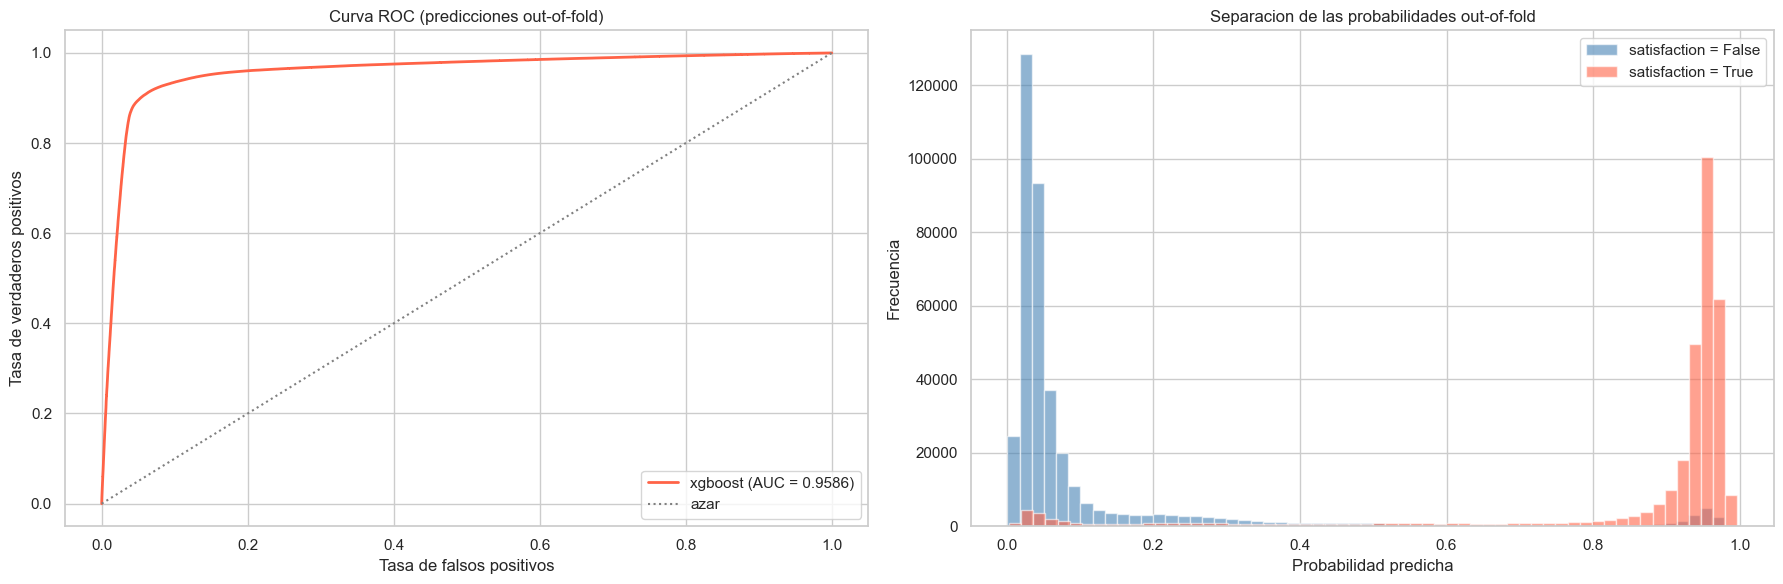

In [6]:
oof     = res["oof"]
auc_oof = roc_auc_score(y, oof)
print(f"AUC out-of-fold ({MEJOR}): {auc_oof:.5f}")

fpr, tpr, _ = roc_curve(y, oof)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes[0].plot(fpr, tpr, color="tomato", lw=2, label=f"xgboost (AUC = {auc_oof:.4f})")
axes[0].plot([0, 1], [0, 1], color="gray", ls=":", lw=1.5, label="azar")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].set_title("Curva ROC (predicciones out-of-fold)")
axes[0].legend(loc="lower right")
for cls, color, etiqueta in [(0, "steelblue", "False"), (1, "tomato", "True")]:
    axes[1].hist(oof[y == cls], bins=60, alpha=0.6, color=color,
                 label=f"satisfaction = {etiqueta}")
axes[1].set_xlabel("Probabilidad predicha")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title("Separacion de las probabilidades out-of-fold")
axes[1].legend()
plt.tight_layout()
plt.show()

In [7]:
# AUC dentro de cada segmento, contra el logit: el punto debil de 2_logit eran los viajes personales
oof_logit = np.load("../models/2_logit_oof.npy")
seg = pd.DataFrame({"y": y, "xgb": oof, "logit": oof_logit,
                    "travel": train["Type of Travel"].astype(str), "clase": train["Class"].astype(str)})


def auc_seg(g, col):
    return roc_auc_score(g["y"], g[col]) if g["y"].nunique() > 1 else np.nan


tabla = seg.groupby(["travel", "clase"]).apply(
    lambda g: pd.Series({"n": len(g), "tasa": g["y"].mean(),
                         "auc_logit": auc_seg(g, "logit"), "auc_xgb": auc_seg(g, "xgb")}))
tabla["delta"] = tabla["auc_xgb"] - tabla["auc_logit"]
print(tabla.round(4).to_string())

                                 n    tasa  auc_logit  auc_xgb   delta
travel          clase                                                 
Business travel Business  338272.0  0.7325     0.9188   0.9318  0.0131
                Eco       141612.0  0.2600     0.9175   0.9330  0.0155
                Eco Plus   17557.0  0.3464     0.9187   0.9408  0.0221
Personal Travel Business    3940.0  0.1119     0.7882   0.8026  0.0144
                Eco       185792.0  0.0971     0.8050   0.8279  0.0229
                Eco Plus   12462.0  0.0954     0.8008   0.8274  0.0266


## 5. Feature Importance

Con early stopping cada fold corta en un `best_iteration` distinto, así que no hay un único "modelo
final": la importancia se promedia entre los 5 modelos y se muestra el desvío como barra de error.

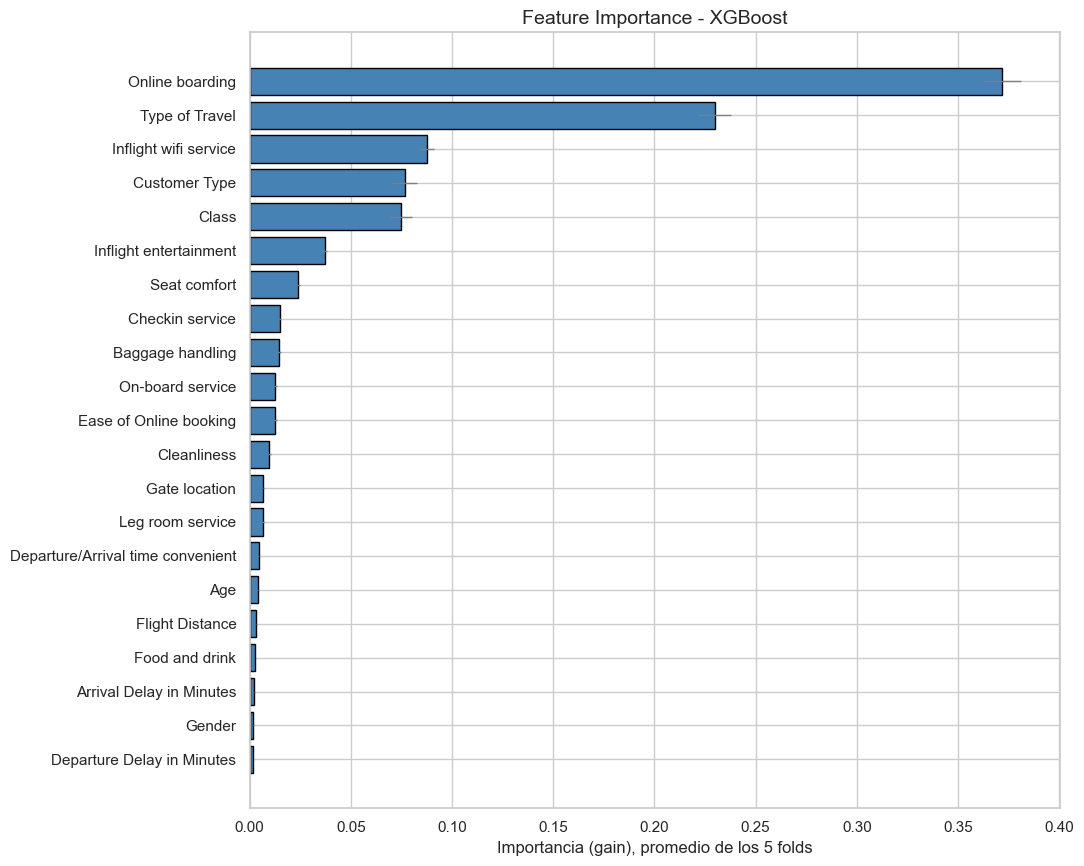

Ordenada por importancia:
Online boarding                      0.3716
Type of Travel                       0.2299
Inflight wifi service                0.0877
Customer Type                        0.0766
Class                                0.0749
Inflight entertainment               0.0371
Seat comfort                         0.0240
Checkin service                      0.0149
Baggage handling                     0.0145
On-board service                     0.0128
Ease of Online booking               0.0125
Cleanliness                          0.0098
Gate location                        0.0067
Leg room service                     0.0066
Departure/Arrival time convenient    0.0044
Age                                  0.0040
Flight Distance                      0.0033
Food and drink                       0.0026
Arrival Delay in Minutes             0.0024
Gender                               0.0018
Departure Delay in Minutes           0.0018


In [8]:
imps      = pd.DataFrame([m.feature_importances_ for m in res["modelos"]], columns=features)
imp_media = imps.mean().sort_values()
imp_std   = imps.std().reindex(imp_media.index)

fig, ax = plt.subplots(figsize=(11, max(6, len(features) * 0.42)))
ax.barh(imp_media.index, imp_media.values, xerr=imp_std.values,
        color="steelblue", edgecolor="black", error_kw=dict(ecolor="gray", lw=1))
ax.set_xlabel("Importancia (gain), promedio de los 5 folds")
ax.set_title("Feature Importance - XGBoost", fontsize=14)
plt.tight_layout()
plt.show()

print("Ordenada por importancia:")
print(imp_media.sort_values(ascending=False).round(4).to_string())

## 6. Comparación con el Logit

In [9]:
AUC_LOGIT_CV = 0.94908   # CV AUC de 2_logit.ipynb (E. D + cruces de viaje)

print(f"{'='*66}")
print("COMPARATIVA DE MODELOS")
print(f"{'='*66}")
print(f"  Logit (2_logit.ipynb)       CV AUC = {AUC_LOGIT_CV:.5f}")
print(f"  XGBoost ({MEJOR})            CV AUC = {cv_mean:.5f}")
print(f"{'='*66}")
print(f"  Ganancia de XGBoost sobre el logit: {cv_mean - AUC_LOGIT_CV:+.5f}")
print(f"  Desvio entre folds de XGBoost:      {np.std(res['aucs']):.5f}")

# Cuanto de nuevo aporta XGBoost sobre el logit: si ordenan casi igual, ensamblarlos no suma.
print(f"\nCorrelacion de Spearman OOF logit vs OOF xgboost: "
      f"{pd.Series(oof_logit).corr(pd.Series(oof), method='spearman'):.4f}")
for w in [0.1, 0.2, 0.3]:
    mezcla = (1 - w) * pd.Series(oof).rank() + w * pd.Series(oof_logit).rank()
    print(f"  Mezcla de rankings con {w:.0%} de logit: AUC OOF = {roc_auc_score(y, mezcla):.5f}")

COMPARATIVA DE MODELOS
  Logit (2_logit.ipynb)       CV AUC = 0.94908
  XGBoost (crudas)            CV AUC = 0.95858
  Ganancia de XGBoost sobre el logit: +0.00950
  Desvio entre folds de XGBoost:      0.00066

Correlacion de Spearman OOF logit vs OOF xgboost: 0.8872
  Mezcla de rankings con 10% de logit: AUC OOF = 0.95849
  Mezcla de rankings con 20% de logit: AUC OOF = 0.95822
  Mezcla de rankings con 30% de logit: AUC OOF = 0.95780


## 7. Predicción sobre Test y Submission

In [10]:
proba_test = res["test"]

submission = pd.DataFrame({"id": test["id"], TARGET: proba_test})
submission.to_csv("../submissions/3_xgboost_submission.csv", index=False)

# OOF y predicciones de test para un ensamble futuro (models/ esta gitignoreado)
np.save("../models/3_xgboost_oof.npy",  oof)
np.save("../models/3_xgboost_test.npy", proba_test)

print(f"Submission escrita: ../submissions/3_xgboost_submission.csv ({len(submission):,} filas)")
print(submission.head().to_string(index=False))
print(f"\nProbabilidad media predicha: {proba_test.mean():.4f}"
      f"  (tasa base en train: {y.mean():.4f})")

Submission escrita: ../submissions/3_xgboost_submission.csv (299,844 filas)
    id  satisfaction
699635      0.241150
699636      0.893421
699637      0.900839
699638      0.069306
699639      0.055750

Probabilidad media predicha: 0.4437  (tasa base en train: 0.4436)


In [11]:
# Chequeo de sanidad contra sample_submission (formato e ids)
sample = pd.read_csv("../data/sample_submission.csv")
assert list(submission.columns) == list(sample.columns), "columnas no coinciden"
assert len(submission) == len(sample), "cantidad de filas no coincide"
assert (submission["id"].values == sample["id"].values).all(), "los ids no estan alineados"
assert submission[TARGET].between(0, 1).all(), "hay probabilidades fuera de [0, 1]"
assert submission[TARGET].notna().all(), "hay nulos en la prediccion"
print("Chequeos OK - submission lista para enviar.")

Chequeos OK - submission lista para enviar.


## 8. Envío a Kaggle vía API

In [12]:
COMPETITION = "playground-series-s6e10"
FILE        = "../submissions/3_xgboost_submission.csv"
MSG         = f"XGBoost - {MEJOR} - cat nativas - CV AUC={cv_mean:.5f}"

!kaggle competitions submit -c {COMPETITION} -f "{FILE}" -m "{MSG}"

9 submissions remaining today.


  0%|          | 0.00/5.43M [00:00<?, ?B/s]
  0%|          | 16.0k/5.43M [00:00<00:56, 100kB/s]
 10%|▉         | 544k/5.43M [00:00<00:05, 1.01MB/s]
 11%|█         | 624k/5.43M [00:00<00:06, 811kB/s] 
 13%|█▎        | 704k/5.43M [00:00<00:07, 676kB/s]
 73%|███████▎  | 3.98M/5.43M [00:01<00:00, 7.12MB/s]
100%|██████████| 5.43M/5.43M [00:01<00:00, 2.97MB/s]



Successfully submitted to Predicting Airline Satisfaction


In [13]:
# Score publico de los envios (esperar unos segundos a que Kaggle lo puntue)
!kaggle competitions submissions -c {COMPETITION}

     ref  fileName                  date                        description                                              status                     publicScore  privateScore  
--------  ------------------------  --------------------------  -------------------------------------------------------  -------------------------  -----------  ------------  
57370373  3_xgboost_submission.csv  2026-10-18 22:04:16.173000  XGBoost - crudas - cat nativas - CV AUC=0.95858          SubmissionStatus.PENDING                              
57027840  2_logit_submission.csv    2026-10-10 02:02:02.677000  Logit - E. D + cruces de viaje - C=0.1 - CV AUC=0.94908  SubmissionStatus.COMPLETE  0.94857                    


## 9. Conclusiones

- **CV AUC = 0,95858** (± 0,00066 entre folds) y 0,95857 out-of-fold, con las 21 features crudas y sin ningún feature engineering. El early stopping cortó en 286 árboles de media, entre 188 y 339 según el fold.
- **+0,00950 sobre el logit** (0,94908 → 0,95858), más de 14 veces el desvío entre folds. Las interacciones que el logit no podía representar valían bastante más que todo el feature engineering que se le hizo a mano.
- **Mejora en los seis segmentos** de tipo de viaje × clase, y más donde el logit era más flojo: +0,023 a +0,027 en viajes personales en Eco y Eco Plus, contra +0,013 a +0,016 en Business y Eco de trabajo. Aun así, los viajes personales siguen siendo el punto débil, con AUC de 0,80-0,83 contra 0,93-0,94 en los de trabajo.
- **La importancia se concentra en `Online boarding` (37,2 % del gain) y `Type of Travel` (23,0 %)**. `Type of Travel` era sólo la quinta variable por AUC univariado (0,70), pero un corte cerca de la raíz separa dos poblaciones donde el resto de las variables funciona distinto. Es la misma interacción que el logit no lograba representar.
- **Las variables que el EDA marcó como ruido también quedan abajo acá**: `Gender`, las dos demoras, `Food and drink`, `Age` y `Flight Distance` suman menos del 2 % del gain entre todas. Con `Age` y `Flight Distance` hay una diferencia: en el logit sus tramos sí aportaban, y acá su señal parece quedar absorbida por `Type of Travel` y `Class`.
- **Mezclar con el logit no suma**: aunque la correlación de Spearman entre los OOF es 0,887 (bastante diversidad), cualquier peso al logit baja el AUC (0,95849 con 10 %, 0,95780 con 30 %). El logit no tiene información que XGBoost no haya capturado.
- **Sin shift**: la probabilidad media predicha en test (0,4437) coincide con la tasa base (0,4436).
- **Referencia de leaderboard**: el logit dio 0,94857 de score público contra 0,94908 de CV (0,00051 por debajo). El envío de XGBoost quedó pendiente de puntuación al momento de ejecutar.